# 06 · Curve Momentum / Basis-Momentum (D)

用 **K=5 ex-ante main pair** 跑 idea D 的第一个 baseline：**within-commodity curve momentum**。

- 每个商品内部，比较 near rank 和 far rank 过去 12 个月的累计收益；
- long 收益高的腿、short 收益低的腿；
- 每月最后一个交易日更新 signal，t+1 收盘成交；
- signal 在数学上就是 **basis-momentum**：
  `BM = cumulative(near) - cumulative(far)`。

参考：Paschke, Prokopczuk & Wese Simen (2020) *Curve Momentum*；
Boons & Porras Prado (2019) *Basis-Momentum*。

这不是 robustness 全集，只回答一个问题：**D 在这个 K=5 baseline 里有没有 edge。**


In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
Path("output").mkdir(exist_ok=True)


In [2]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import panel, signals, backtest, metrics


## 1. K=5 backtest panel

D=10 的研究面板保持不变；回测使用独立的 K=5 ex-ante 面板。
主 pair 约 2/3 时间是 M1–M2，1/3 时间是 M2–M3。


In [3]:
rank = pd.read_parquet("data/processed/rank.parquet")
bt = panel.build_backtest_panel(rank, d=None, k=5)
returns = panel.build_return_panel(bt["rank"], bt["contract"])

print("K=5 pair-dates:", bt["spread"].shape[0])
print("return rows:", returns.shape[0])
print(bt["spread"]["pair_rank_mix"].value_counts().to_string())


K=5 pair-dates: 236385
return rows: 1013664
pair_rank_mix
M1-M2    159817
M2-M3     76568


## 2. Curve-momentum signal

`curve_momentum_signal` 用 `ret_rank` 建 rank return index；12 个月窗口内：
- 至少 80% 有效收益；
- 如果窗口里出现负价格或 `ret_rank <= -1`，signal = NaN；
- target 只在 month-end 更新，并向前填充到下一个 month-end。


In [4]:
sig = signals.curve_momentum_signal(bt["spread"], returns)

print("signal rows:", sig.shape[0])
print("signal dates:", int(sig["is_signal_date"].sum()))
print(sig["target"].value_counts(dropna=False).to_string())
display(sig.loc[sig["is_signal_date"]].head(3))


signal rows: 243699
signal dates: 11313
target
 1.0    123155
-1.0    112924
 0.0      7620


,date,root,commodity,sector,target,score,is_signal_date,rank_near,rank_far,mom_near,mom_far
336,1986-01-31,BO,Soybean Oil,Oilseeds,0.0,NaN,True,1.0,2.0,NaN,NaN
337,1986-01-31,C,Corn,Grains,0.0,NaN,True,1.0,2.0,NaN,NaN
338,1986-01-31,CC,Cocoa,Softs,0.0,NaN,True,1.0,2.0,NaN,NaN


## 3. Target legs

`build_target_legs` 把 signal 展开成腿级目标：long spread = near +1 / far −1。


In [5]:
targets = backtest.build_target_legs(sig, bt["spread"])
print("target leg rows:", targets.shape[0])
example = targets.loc[
    (targets["root"] == "CL") & (targets["date"] == "2021-10-01")
]
display(example)


target leg rows: 457934


,date,root,commodity,sector,group_id,contract,units,leg,target
399278,2021-10-01,CL,WTI Crude Oil,Energy,CL_CLX21_CLZ21,CLZ21,1.0,far,-1.0
399279,2021-10-01,CL,WTI Crude Oil,Energy,CL_CLX21_CLZ21,CLX21,-1.0,near,-1.0


## 4. Backtest

Engine 是按天 event loop；monthly rebalance、roll、missing/stale、pending order
都是 path-dependent。Full sample 和 test 分开跑，test 从 2016 开始空仓。


In [6]:
contracts = sorted(
    set(bt["spread"]["contract_near"].dropna())
    | set(bt["spread"]["contract_far"].dropna())
)
mark = panel.build_contract_mark_state(bt["contract"], contracts=contracts)

cfg = backtest.BacktestConfig(rebalance="last_trading_day_of_month")
full = backtest.run_backtest(
    bt["spread"], bt["contract"], targets, cfg, mark_state=mark
)
test = backtest.run_backtest(
    bt["spread"],
    bt["contract"],
    targets,
    backtest.BacktestConfig(
        rebalance="last_trading_day_of_month", start_date="2016-01-01"
    ),
    mark_state=mark,
)
print("full:", full.portfolio_returns.shape)
print("test:", test.portfolio_returns.shape)


full: (10507, 6)
test: (2786, 6)


## 5. Summary

Gross 和 net 都报。Turnover 是 one-way traded notional / 平均 portfolio gross / 年。


In [7]:
summary = pd.concat(
    [
        metrics.summarize(full).assign(period="full"),
        metrics.summarize(full, end="2015-12-31").assign(period="train"),
        metrics.summarize(test).assign(period="test"),
    ],
    ignore_index=True,
)
summary.to_csv("output/curve_momentum_summary.csv", index=False)
display(summary)


,start,end,n_days,years,ann_return_gross,ann_return_net,ann_vol_gross,ann_vol_net,sharpe_gross,sharpe_net,max_drawdown_net,hit_rate_net,avg_N_t,avg_net_exposure,n_trades,turnover,period
0,1986-01-02,2026-10-13,10507,41.694444,0.005455,-0.009856,0.014831,0.015004,0.023574,-0.041113,-0.347993,0.468576,22.269915,0.002552,45435,16.120102,full
1,1986-01-02,2015-12-31,7721,30.638889,0.008500,-0.006477,0.011014,0.011189,0.048755,-0.036233,-0.186742,0.478851,21.828002,0.002026,32008,15.598909,train
2,2016-01-04,2026-10-13,2786,11.055556,-0.002766,-0.018949,0.022202,0.022397,-0.007164,-0.053102,-0.196407,0.441601,23.391960,0.004023,13356,16.803821,test


## 6. Sector


In [8]:
sector = metrics.sector_summary(full)
sector.to_csv("output/curve_momentum_sector.csv", index=False)
display(sector)


,sector,n_days,ann_return_gross,ann_vol_gross,sharpe_gross
0,Energy,10216,0.015125,0.061171,0.275536
1,Grains,9996,0.004843,0.020043,0.251079
2,Industrials,10000,-0.007561,0.037564,-0.183194
3,Livestock,10007,0.001231,0.022449,0.066021
4,Metals,9974,0.000265,0.007669,0.038353
5,Oilseeds,9992,0.006524,0.014216,0.464501
6,Softs,9982,0.001871,0.023349,0.091734


## 7. Static benchmark

两个静态 benchmark：始终 long near / short far（+1），以及反过来（−1）。
用来判断 D 的 dynamic timing 是否比一个固定方向更好。


In [9]:
def run_static(sign: float) -> pd.Series:
    static_signal = bt["spread"][["date", "root"]].copy()
    static_signal["target"] = sign
    static_targets = backtest.build_target_legs(static_signal, bt["spread"])
    result = backtest.run_backtest(
        bt["spread"], bt["contract"], static_targets, cfg, mark_state=mark
    )
    return metrics.summarize(result).assign(period=f"static_{int(sign):+d}")

static = pd.concat([run_static(1.0), run_static(-1.0)], ignore_index=True)
static.to_csv("output/curve_momentum_static.csv", index=False)
display(static)


,start,end,n_days,years,ann_return_gross,ann_return_net,ann_vol_gross,ann_vol_net,sharpe_gross,sharpe_net,max_drawdown_net,hit_rate_net,avg_N_t,avg_net_exposure,n_trades,turnover,period
0,1986-01-02,2026-10-13,10507,41.694444,0.003522,-0.008396,0.015173,0.015343,0.015079,-0.034133,-0.307413,0.477979,22.950509,-0.002351,39316,11.361076,static_+1
1,1986-01-02,2026-10-13,10507,41.694444,-0.003740,-0.015572,0.015173,0.015340,-0.015079,-0.063966,-0.486206,0.465872,22.950509,0.002351,39316,11.361076,static_-1


## 8. Monthly Sharpe + block bootstrap

D 的 signal 有很强的持续性；日度 Sharpe 可能高估显著性。
这里按 month-end 重采样算月度 Sharpe，并用 month-level block bootstrap
复核均值。


In [10]:
def monthly_stats(result, label: str) -> pd.Series:
    pr = result.portfolio_returns.set_index("date")["return_net"]
    monthly = ((1.0 + pr).resample("ME").prod() - 1.0).dropna()
    return pd.Series(
        {
            "period": label,
            "n_months": len(monthly),
            "monthly_mean": monthly.mean(),
            "monthly_vol": monthly.std(ddof=1),
            "monthly_sharpe": monthly.mean() / monthly.std(ddof=1) * np.sqrt(12.0),
        }
    )

def block_bootstrap(result, label: str, n_boot: int = 2000, seed: int = 0) -> pd.Series:
    pr = result.portfolio_returns.set_index("date")["return_net"]
    monthly = ((1.0 + pr).resample("ME").prod() - 1.0).dropna()
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(monthly), size=(n_boot, len(monthly)))
    means = monthly.to_numpy()[idx].mean(axis=1)
    return pd.Series(
        {
            "period": label,
            "mean": means.mean(),
            "se": means.std(ddof=1),
            "t_stat": means.mean() / means.std(ddof=1),
            "n_months": len(monthly),
        }
    )

monthly = pd.concat(
    [
        monthly_stats(full, "full"),
        monthly_stats(metrics._slice(full, None, "2015-12-31"), "train"),
        monthly_stats(test, "test"),
    ],
    axis=1,
).T
monthly.to_csv("output/curve_momentum_monthly.csv", index=False)
display(monthly)

boot = pd.concat(
    [block_bootstrap(full, "full"), block_bootstrap(test, "test")], axis=1
).T
boot.to_csv("output/curve_momentum_bootstrap.csv", index=False)
display(boot)


,period,n_months,monthly_mean,monthly_vol,monthly_sharpe
0,full,490,-0.000837,0.003212,-0.903021
1,train,360,-0.000548,0.003098,-0.612784
2,test,130,-0.00162,0.003377,-1.661717


,period,mean,se,t_stat,n_months
0,full,-0.00084,0.000143,-5.871953,490
1,test,-0.00163,0.000301,-5.412241,130


## 9. Cumulative return


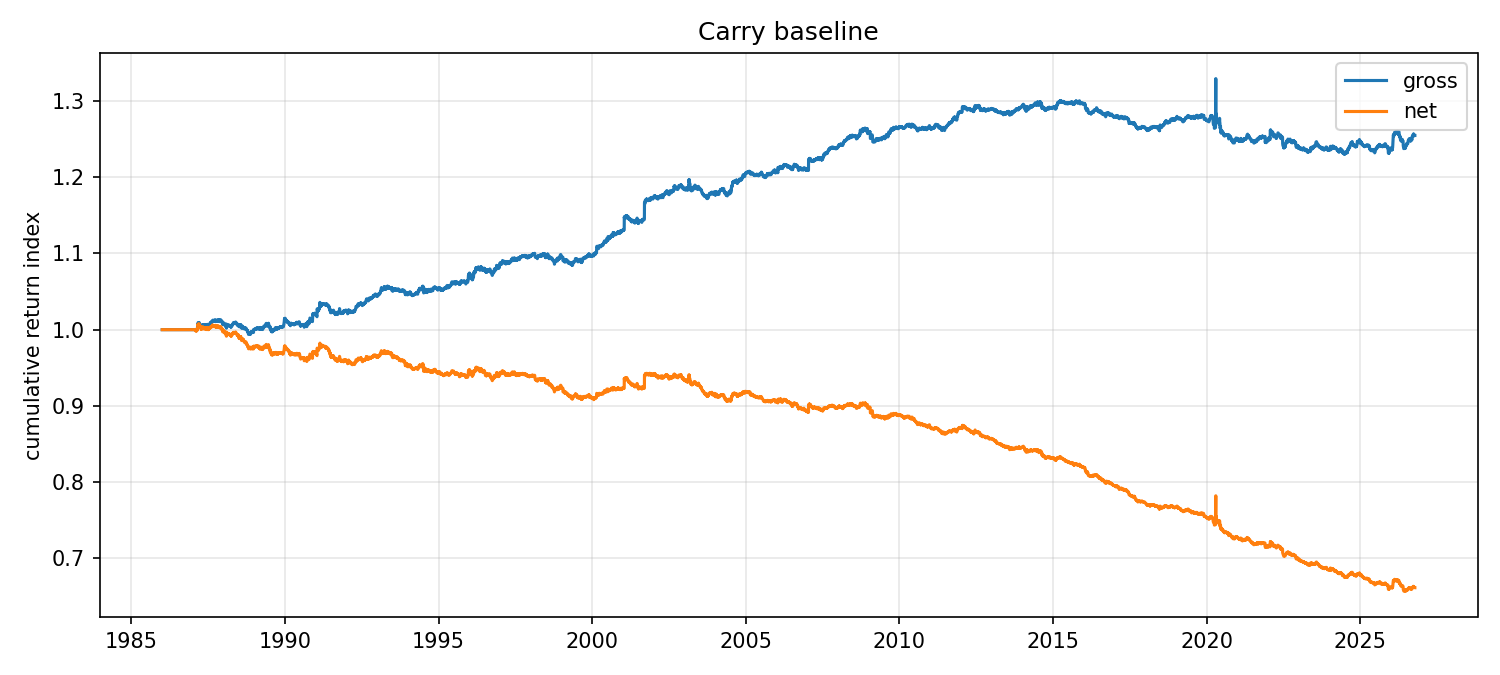

In [11]:
path = metrics.plot_result(full, "output/curve_momentum_cumulative.png")
display(Image(filename=str(path)))


## 10. 读这个 baseline

这是 minimal D baseline：N=2 main pair、12 个月 formation、monthly、
±1、5 bps/leg、no liquidity filter。

| Period | Gross ann. | Net ann. | Sharpe net | Max DD net | Turnover |
|---|---:|---:|---:|---:|---:|
| Full 1986–2026 | +0.55% | −0.99% | −0.04 | −34.8% | 16.1× |
| Train 1986–2015 | +0.85% | −0.65% | −0.04 | −18.7% | 15.6× |
| Test 2016–2026 | −0.28% | −1.89% | −0.05 | −19.6% | 16.8× |

- 成本拖累约 1.5%/yr；gross 很弱，test 的 gross 已经为负。
- Static benchmark：always +1 gross +0.35% / net −0.84%，turnover 11.4×；
  always −1 gross −0.37% / net −1.56%。D 的 gross 略高于 static +1，
  但 turnover 更高，net 更差；dynamic timing 没有带来可交易的增量。
- Sector gross：Energy +1.51%、Oilseeds +0.65%、Grains +0.48%、
  Softs +0.19%、Livestock +0.12%、Metals +0.03%、Industrials −0.76%。
- Monthly Sharpe：full −0.90、train −0.61、test −1.66；month-level block
  bootstrap 的 t-stat 为 full −5.87、test −5.41。月度层面显著为负。
- CL 2020-04-20 负价格：affected 12 个月窗口的 score 为 NaN，target 为 0；
  没有 stale signal。
- 结论：D 在这个最简 K=5 baseline 里没有可交易 edge。这是 documented
  negative/mixed result，不用 test set 调参。D-x（cross-sectional
  basis-momentum）是单独的 backlog，不混入 D。
